In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn networkx neo4j joblib scipy streamlit google-genai

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached neo4j-6.4.0-py3-none-any.whl.metadata (5.5 kB)
  Using cached streamlit-1.65.0-py3-none-any.whl.metadata (10 kB)
  Using cached google_genai-2.29.0-py3-none-any.whl.metadata (57 kB)
  Using cached pytz-2026.5-py2.py3-none-any.whl.metadata (22 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached pyarrow-25.0.1-cp311-cp311-win_amd64.whl.metadata (3.0 kB)
  Using cached toml-0.10.2-py2.py3-none-any.whl.metadata (7.1 kB)
  Using cached starlette-1.7.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached httptools-0.9.0-cp311-cp311-win_amd64.whl.metadata (3.

In [2]:
from pathlib import Path
import json
import re
import warnings
import tomllib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import save_npz

warnings.filterwarnings("ignore")

# Xác định thư mục gốc dù notebook mở từ root hay từ notebooks
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() == "notebooks":
    BASE_DIR = CURRENT_DIR.parent
else:
    BASE_DIR = CURRENT_DIR

DATA_DIR = BASE_DIR / "data"
KB_DIR = BASE_DIR / "knowledge_base"
MODEL_DIR = BASE_DIR / "models"
OUTPUT_DIR = BASE_DIR / "outputs"
SCREENSHOT_DIR = BASE_DIR / "screenshots"

DIABETES_PATH = DATA_DIR / "diabetes" / "diabetes.csv"
STOCK_PATH = DATA_DIR / "stock" / "AAPL_stock_data.csv"

for folder in [
    KB_DIR / "diabetes",
    KB_DIR / "stock",
    MODEL_DIR,
    OUTPUT_DIR,
    SCREENSHOT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Thư mục dự án:", BASE_DIR)
print("Diabetes file:", DIABETES_PATH.exists())
print("Stock file:", STOCK_PATH.exists())

if not DIABETES_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy: {DIABETES_PATH}")

if not STOCK_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy: {STOCK_PATH}")

Thư mục dự án: D:\PTHTTM_TieuLuan02
Diabetes file: True
Stock file: True


In [3]:
diabetes_df = pd.read_csv(DIABETES_PATH)
stock_df = pd.read_csv(STOCK_PATH)

# Chuẩn hóa tên cột
diabetes_df.columns = [
    str(c).strip().replace(" ", "_")
    for c in diabetes_df.columns
]

stock_df.columns = [
    str(c).strip().replace(" ", "_")
    for c in stock_df.columns
]

print("===== DIABETES =====")
print("Kích thước:", diabetes_df.shape)
print("Các cột:", diabetes_df.columns.tolist())
display(diabetes_df.head())

print("\n===== STOCK =====")
print("Kích thước:", stock_df.shape)
print("Các cột:", stock_df.columns.tolist())
display(stock_df.head())

print("\nGiá trị thiếu Diabetes:")
display(diabetes_df.isnull().sum().to_frame("missing"))

print("\nGiá trị thiếu Stock:")
display(stock_df.isnull().sum().to_frame("missing"))

===== DIABETES =====
Kích thước: (768, 9)
Các cột: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



===== STOCK =====
Kích thước: (10971, 8)
Các cột: ['Unnamed:_0', 'open', 'high', 'low', 'close', 'adjclose', 'volume', 'ticker']


,Unnamed:_0,open,high,low,close,adjclose,volume,ticker
0,1980-12-12,0.128348,0.128906,0.128348,0.128348,0.099192,469033600,AAPL
1,1980-12-15,0.122210,0.122210,0.121652,0.121652,0.094017,175884800,AAPL
2,1980-12-16,0.113281,0.113281,0.112723,0.112723,0.087117,105728000,AAPL
3,1980-12-17,0.115513,0.116071,0.115513,0.115513,0.089273,86441600,AAPL
4,1980-12-18,0.118862,0.119420,0.118862,0.118862,0.091861,73449600,AAPL



Giá trị thiếu Diabetes:


,missing
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Giá trị thiếu Stock:


,missing
Unnamed:_0,0
open,0
high,0
low,0
close,0
adjclose,0
volume,0
ticker,0


In [7]:
# Chuẩn hóa dataset diabetes
if "Outcome" not in diabetes_df.columns:
    raise ValueError(
        "Không tìm thấy cột Outcome trong diabetes.csv. "
        "Hãy kiểm tra đúng dataset Pima Indians Diabetes."
    )

diabetes_df["Outcome"] = pd.to_numeric(
    diabetes_df["Outcome"], errors="coerce"
)

diabetes_df = diabetes_df.dropna(
    subset=["Outcome"]
).copy()

diabetes_df["Outcome"] = diabetes_df["Outcome"].astype(int)

if not set(diabetes_df["Outcome"].unique()).issubset({0, 1}):
    raise ValueError("Outcome phải có nhãn 0 và 1.")

# Hàm tìm cột theo tên thông dụng
def find_column(columns, candidates):
    lookup = {
        str(c).lower().replace("_", " ").strip(): c
        for c in columns
    }

    for candidate in candidates:
        key = candidate.lower().replace("_", " ").strip()
        if key in lookup:
            return lookup[key]

    return None


date_col = find_column(
    stock_df.columns,
    ["Date", "Datetime", "Timestamp", "Unnamed: 0"]
)

close_col = find_column(
    stock_df.columns,
    ["Close", "Adj Close", "Adjusted Close", "Adj_Close", "close", "adjclose"]
)


if date_col is None or close_col is None:
    raise ValueError(
        "Không tìm được cột ngày hoặc giá đóng cửa. "
        f"Các cột hiện có: {stock_df.columns.tolist()}"
    )

stock_df[date_col] = pd.to_datetime(
    stock_df[date_col], errors="coerce"
)

stock_df[close_col] = pd.to_numeric(
    stock_df[close_col], errors="coerce"
)

stock_df = (
    stock_df
    .dropna(subset=[date_col, close_col])
    .sort_values(date_col)
    .drop_duplicates(subset=[date_col], keep="last")
    .reset_index(drop=True)
)

if len(stock_df) == 0:
    raise ValueError("Không còn bản ghi cổ phiếu hợp lệ.")

print("Diabetes sau kiểm tra:", diabetes_df.shape)
print("Stock sau kiểm tra:", stock_df.shape)
print("Cột ngày:", date_col)
print("Cột giá đóng cửa:", close_col)

display(diabetes_df.head())
display(stock_df.head())

Diabetes sau kiểm tra: (768, 9)
Stock sau kiểm tra: (10971, 8)
Cột ngày: Unnamed:_0
Cột giá đóng cửa: close


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,Unnamed:_0,open,high,low,close,adjclose,volume,ticker
0,1980-12-12,0.128348,0.128906,0.128348,0.128348,0.099192,469033600,AAPL
1,1980-12-15,0.122210,0.122210,0.121652,0.121652,0.094017,175884800,AAPL
2,1980-12-16,0.113281,0.113281,0.112723,0.112723,0.087117,105728000,AAPL
3,1980-12-17,0.115513,0.116071,0.115513,0.115513,0.089273,86441600,AAPL
4,1980-12-18,0.118862,0.119420,0.118862,0.118862,0.091861,73449600,AAPL


Thống kê Diabetes:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Thống kê Stock:


,count,mean,min,25%,50%,75%,max,std
Unnamed:_0,10971,2002-09-07 00:10:53.650533,1980-12-12 00:00:00,1991-10-17 12:00:00,2002-09-04 00:00:00,2013-07-27 12:00:00,2024-06-20 00:00:00,NaN
open,10971.0,21.808152,0.049665,0.297991,0.526786,19.920358,217.589996,44.979785
high,10971.0,22.043474,0.049665,0.303571,0.535357,20.134821,220.199997,45.464424
low,10971.0,21.583133,0.049107,0.290179,0.515625,19.730357,213.0,44.531168
close,10971.0,21.82243,0.049107,0.297991,0.526786,19.908214,216.669998,45.017703
adjclose,10971.0,21.05494,0.037952,0.242262,0.429012,17.17264,216.669998,44.632965
volume,10971.0,318707063.627381,0.0,113657200.0,206169600.0,399098000.0,7421640800.0,335621528.984065


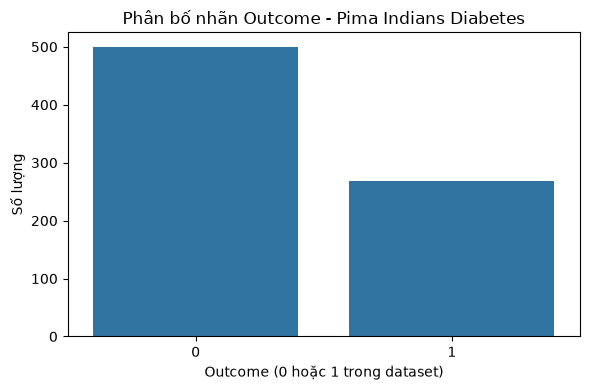

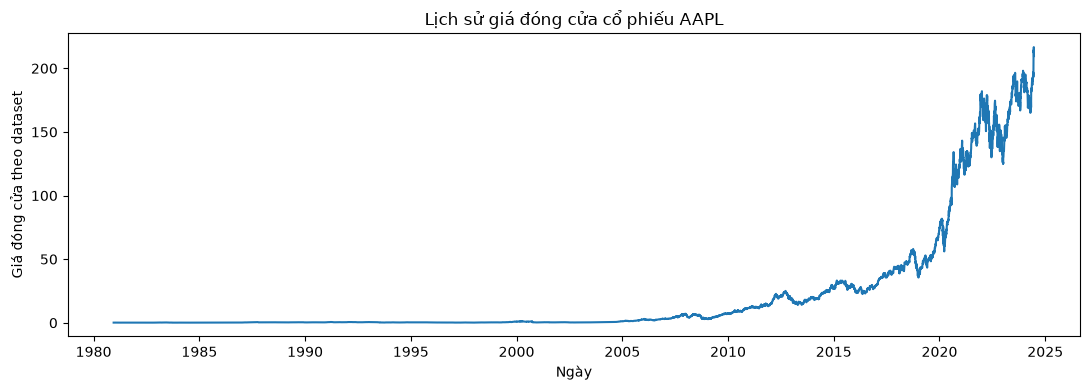

Đã lưu thống kê và biểu đồ vào: D:\PTHTTM_TieuLuan02\outputs


In [12]:
# Thống kê mô tả
diabetes_summary = diabetes_df.describe().T
stock_summary = stock_df.describe().T

print("Thống kê Diabetes:")
display(diabetes_summary)

print("Thống kê Stock:")
display(stock_summary)

# Phân bố Outcome
plt.figure(figsize=(6, 4))
sns.countplot(data=diabetes_df, x="Outcome")
plt.title("Phân bố nhãn Outcome - Pima Indians Diabetes")
plt.xlabel("Outcome (0 hoặc 1 trong dataset)")
plt.ylabel("Số lượng")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "diabetes_outcome_distribution.png",
    dpi=160
)
plt.show()

# Giá đóng cửa lịch sử
plt.figure(figsize=(11, 4))
plt.plot(stock_df[date_col], stock_df[close_col])
plt.title("Lịch sử giá đóng cửa cổ phiếu AAPL")
plt.xlabel("Ngày")
plt.ylabel("Giá đóng cửa theo dataset")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "aapl_close_price.png",
    dpi=160
)
plt.show()

# Lưu thống kê
diabetes_summary.to_csv(
    OUTPUT_DIR / "diabetes_summary.csv",
    encoding="utf-8-sig"
)

stock_summary.to_csv(
    OUTPUT_DIR / "stock_summary.csv",
    encoding="utf-8-sig"
)

print("Đã lưu thống kê và biểu đồ vào:", OUTPUT_DIR)

In [13]:
feature_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

required_columns = feature_columns + ["Outcome"]

missing_columns = [
    c for c in required_columns
    if c not in diabetes_df.columns
]

if missing_columns:
    raise ValueError(
        f"Dataset thiếu các cột: {missing_columns}"
    )

X = diabetes_df[feature_columns].apply(
    pd.to_numeric, errors="coerce"
)

y = diabetes_df["Outcome"].astype(int)

# Trong dataset này, số 0 ở một số chỉ số sinh học
# thường biểu thị dữ liệu không hợp lệ/không được ghi nhận.
# Chuyển các giá trị đó thành NaN để pipeline xử lý.
zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in zero_as_missing:
    X.loc[X[col] == 0, col] = np.nan

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

diabetes_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

diabetes_pipeline.fit(X_train, y_train)

y_pred = diabetes_pipeline.predict(X_test)
y_prob = diabetes_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

# Lưu pipeline
joblib.dump(
    diabetes_pipeline,
    MODEL_DIR / "diabetes_pipeline.joblib"
)

with open(
    MODEL_DIR / "diabetes_features.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(feature_columns, f, ensure_ascii=False, indent=2)

print("Đã lưu mô hình tại:", MODEL_DIR / "diabetes_pipeline.joblib")

Accuracy: 0.7403
ROC-AUC: 0.8263

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.77      0.79       100
           1       0.62      0.69      0.65        54

    accuracy                           0.74       154
   macro avg       0.72      0.73      0.72       154
weighted avg       0.75      0.74      0.74       154

Confusion matrix:


,Predicted 0,Predicted 1
Actual 0,77,23
Actual 1,17,37


Đã lưu mô hình tại: D:\PTHTTM_TieuLuan02\models\diabetes_pipeline.joblib


,Metric,Value
0,ticker,AAPL
1,source_file,AAPL_stock_data.csv
2,rows,10971
3,start_date,1980-12-12
4,end_date,2024-06-20
5,latest_close_in_dataset,209.649796
6,minimum_close,0.049107
7,maximum_close,216.669998
8,mean_close,21.82243
9,median_close,0.526786


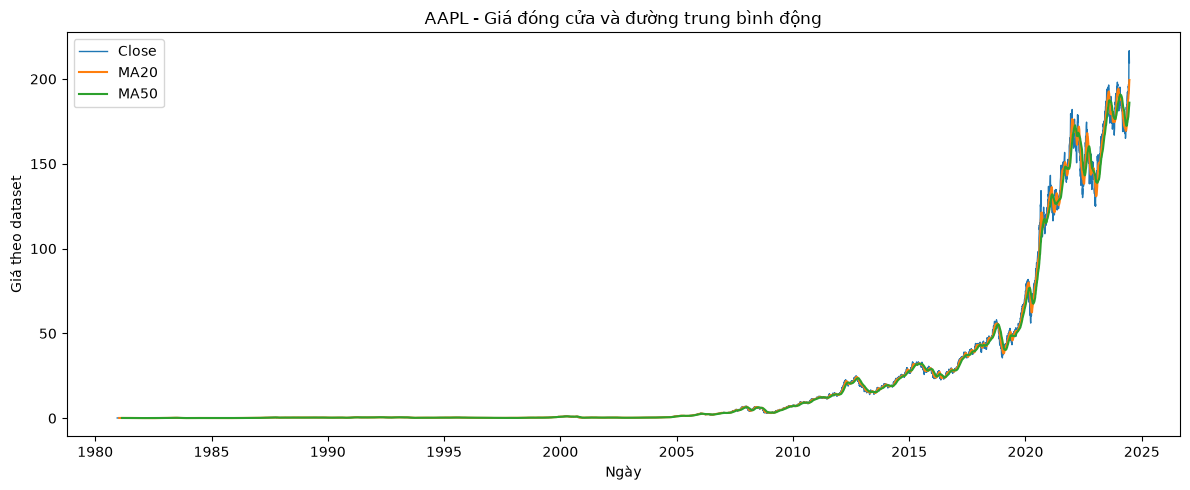

Đã lưu báo cáo và biểu đồ AAPL.


In [14]:
stock_df["Daily_Return_Pct"] = (
    stock_df[close_col].pct_change() * 100
)

stock_df["MA20"] = stock_df[close_col].rolling(20).mean()
stock_df["MA50"] = stock_df[close_col].rolling(50).mean()

first_row = stock_df.iloc[0]
last_row = stock_df.iloc[-1]

stock_report = {
    "ticker": "AAPL",
    "source_file": STOCK_PATH.name,
    "rows": int(len(stock_df)),
    "start_date": str(stock_df[date_col].min().date()),
    "end_date": str(stock_df[date_col].max().date()),
    "latest_close_in_dataset": float(last_row[close_col]),
    "minimum_close": float(stock_df[close_col].min()),
    "maximum_close": float(stock_df[close_col].max()),
    "mean_close": float(stock_df[close_col].mean()),
    "median_close": float(stock_df[close_col].median()),
    "mean_daily_return_pct": float(
        stock_df["Daily_Return_Pct"].mean()
    ),
    "daily_return_std_pct": float(
        stock_df["Daily_Return_Pct"].std()
    )
}

with open(
    OUTPUT_DIR / "aapl_analysis.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(stock_report, f, ensure_ascii=False, indent=2)

display(pd.DataFrame(
    list(stock_report.items()),
    columns=["Metric", "Value"]
))

# Biểu đồ giá và đường trung bình động
plt.figure(figsize=(12, 5))
plt.plot(
    stock_df[date_col],
    stock_df[close_col],
    label="Close",
    linewidth=1
)
plt.plot(
    stock_df[date_col],
    stock_df["MA20"],
    label="MA20"
)
plt.plot(
    stock_df[date_col],
    stock_df["MA50"],
    label="MA50"
)

plt.title("AAPL - Giá đóng cửa và đường trung bình động")
plt.xlabel("Ngày")
plt.ylabel("Giá theo dataset")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "aapl_moving_averages.png",
    dpi=160
)
plt.show()

print("Đã lưu báo cáo và biểu đồ AAPL.")

In [15]:
from neo4j import GraphDatabase

SECRETS_PATH = BASE_DIR / ".streamlit" / "secrets.toml"

if not SECRETS_PATH.exists():
    raise FileNotFoundError(
        "Chưa tạo file .streamlit/secrets.toml"
    )

with open(SECRETS_PATH, "rb") as f:
    config = tomllib.load(f)

driver = GraphDatabase.driver(
    config["NEO4J_URI"],
    auth=(
        config["NEO4J_USERNAME"],
        config["NEO4J_PASSWORD"]
    )
)

driver.verify_connectivity()

print("Kết nối Neo4j thành công!")

Kết nối Neo4j thành công!


In [16]:
cypher = """
MERGE (d:Dataset {name: 'Pima Indians Diabetes'})
MERGE (g:Feature {name: 'Glucose'})
MERGE (b:Feature {name: 'BMI'})
MERGE (bp:Feature {name: 'BloodPressure'})
MERGE (age:Feature {name: 'Age'})
MERGE (o:Label {name: 'Outcome'})
MERGE (m:Model {name: 'Diabetes Prediction Model'})
MERGE (d)-[:CONTAINS_FEATURE]->(g)
MERGE (d)-[:CONTAINS_FEATURE]->(b)
MERGE (d)-[:CONTAINS_FEATURE]->(bp)
MERGE (d)-[:CONTAINS_FEATURE]->(age)
MERGE (d)-[:CONTAINS_LABEL]->(o)
MERGE (m)-[:TRAINED_ON]->(d)
MERGE (m)-[:PREDICTS]->(o)

MERGE (a:Company {name: 'Apple Inc.'})
MERGE (t:Ticker {name: 'AAPL'})
MERGE (s:Dataset {name: 'AAPL Stock History'})
MERGE (date:Feature {name: 'Trading Date'})
MERGE (close:Feature {name: 'Close Price'})
MERGE (ret:Feature {name: 'Daily Return'})
MERGE (a)-[:HAS_TICKER]->(t)
MERGE (t)-[:HAS_DATA]->(s)
MERGE (s)-[:CONTAINS_FIELD]->(date)
MERGE (s)-[:CONTAINS_FIELD]->(close)
MERGE (s)-[:CONTAINS_FIELD]->(ret)
"""

with driver.session(
    database=config["NEO4J_DATABASE"]
) as session:
    session.run(cypher)

print("Đã ghi Knowledge Graph vào Neo4j.")

Đã ghi Knowledge Graph vào Neo4j.


In [17]:
with driver.session(
    database=config["NEO4J_DATABASE"]
) as session:
    result = session.run("""
        MATCH (a)-[r]->(b)
        RETURN
            labels(a) AS source_type,
            a.name AS source,
            type(r) AS relation,
            labels(b) AS target_type,
            b.name AS target
        ORDER BY source, relation
    """)

    graph_rows = [record.data() for record in result]

graph_df = pd.DataFrame(graph_rows)
display(graph_df)

print("Số quan hệ truy vấn được:", len(graph_df))

graph_df.to_csv(
    OUTPUT_DIR / "neo4j_graph_query.csv",
    index=False,
    encoding="utf-8-sig"
)

,source_type,source,relation,target_type,target
0,[Ticker],AAPL,HAS_DATA,[Dataset],AAPL Stock History
1,[Dataset],AAPL Stock History,CONTAINS_FIELD,[Feature],Trading Date
2,[Dataset],AAPL Stock History,CONTAINS_FIELD,[Feature],Close Price
3,[Dataset],AAPL Stock History,CONTAINS_FIELD,[Feature],Daily Return
4,[Company],Apple Inc.,HAS_TICKER,[Ticker],AAPL
5,[Model],Diabetes Prediction Model,PREDICTS,[Label],Outcome
6,[Model],Diabetes Prediction Model,TRAINED_ON,[Dataset],Pima Indians Diabetes
7,[Dataset],Pima Indians Diabetes,CONTAINS_FEATURE,[Feature],Glucose
8,[Dataset],Pima Indians Diabetes,CONTAINS_FEATURE,[Feature],BMI
9,[Dataset],Pima Indians Diabetes,CONTAINS_FEATURE,[Feature],BloodPressure


Số quan hệ truy vấn được: 12


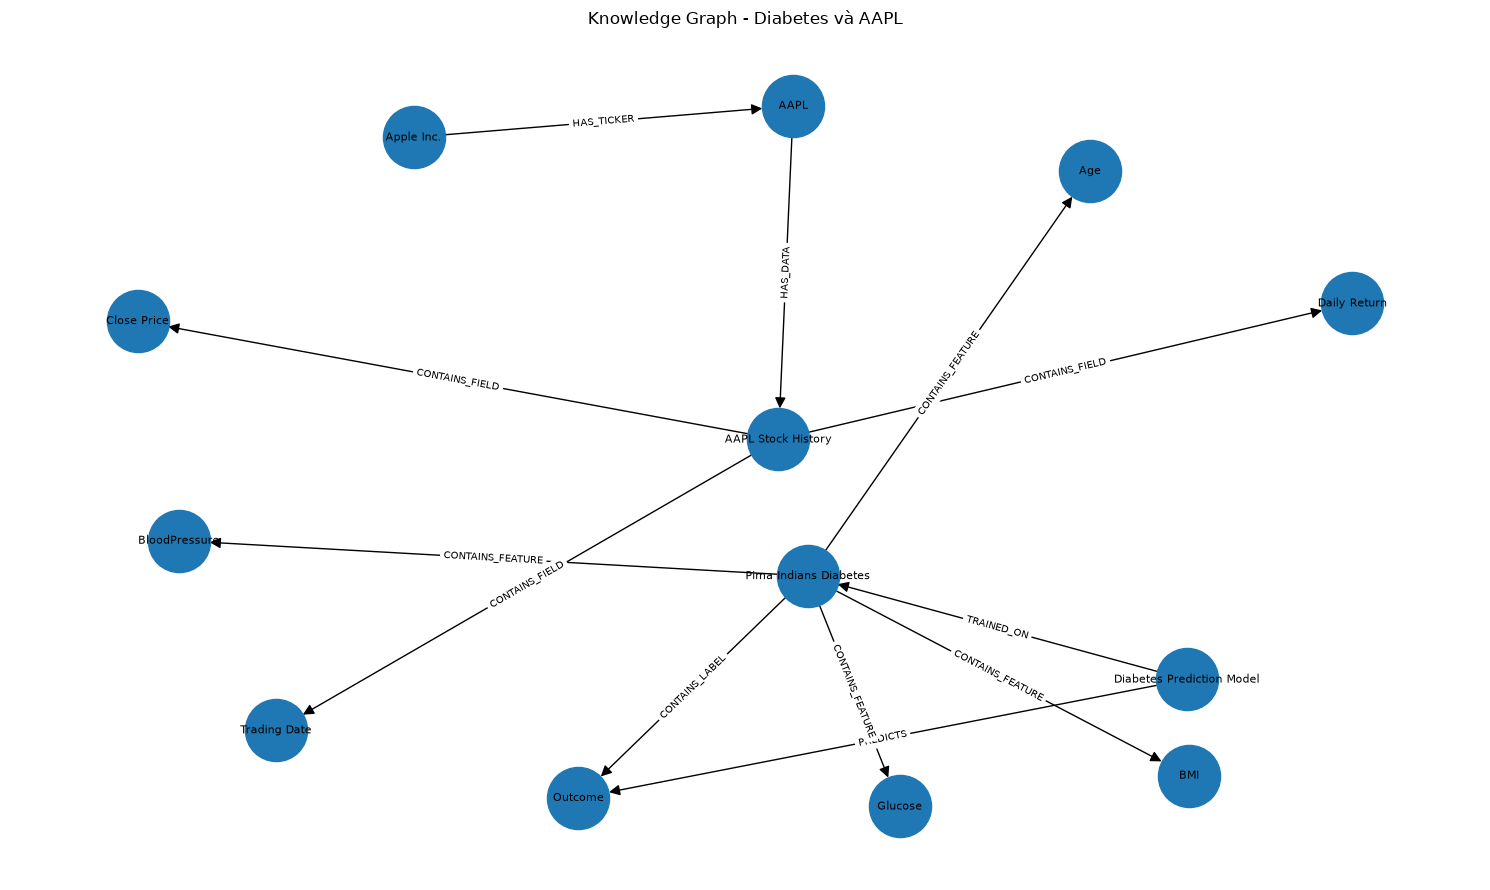

Đã lưu hình và file GraphML.


In [18]:
G = nx.DiGraph()

for _, row in graph_df.iterrows():
    G.add_node(row["source"])
    G.add_node(row["target"])
    G.add_edge(
        row["source"],
        row["target"],
        relation=row["relation"]
    )

plt.figure(figsize=(15, 9))
pos = nx.spring_layout(G, seed=42, k=1.3)

nx.draw_networkx(
    G,
    pos,
    node_size=2000,
    font_size=8,
    arrows=True,
    arrowsize=16
)

edge_labels = {
    (u, v): data["relation"]
    for u, v, data in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=7
)

plt.title("Knowledge Graph - Diabetes và AAPL")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "knowledge_graph.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

nx.write_graphml(
    G,
    OUTPUT_DIR / "knowledge_graph.graphml"
)

print("Đã lưu hình và file GraphML.")

In [19]:
diabetes_docs = {
    "diabetes_overview.txt": """
BỆNH TIỂU ĐƯỜNG - TỔNG QUAN

Tiểu đường là nhóm bệnh chuyển hóa liên quan đến tình trạng glucose
máu tăng. Việc chẩn đoán cần dựa trên xét nghiệm và tiêu chuẩn chuyên môn.
Một mô hình học máy trên bộ dữ liệu nhỏ không thể thay thế bác sĩ
hoặc các xét nghiệm chẩn đoán.

Tài liệu này phục vụ bài tập học máy và hỏi đáp thông tin cơ bản.
""",
    "diabetes_features.txt": """
CÁC ĐẶC TRƯNG TRONG PIMA INDIANS DIABETES

Pregnancies: số lần mang thai trong dataset.
Glucose: chỉ số glucose được ghi nhận.
BloodPressure: huyết áp được ghi nhận.
SkinThickness: độ dày nếp gấp da.
Insulin: chỉ số insulin.
BMI: chỉ số khối cơ thể.
DiabetesPedigreeFunction: đặc trưng liên quan tiền sử gia đình
theo cách biểu diễn của bộ dữ liệu.
Age: tuổi.
Outcome: nhãn 0 hoặc 1 của mẫu trong dataset.

Tên trường cần được đối chiếu với CSV thực tế. Outcome là nhãn dữ liệu,
không phải kết luận chẩn đoán cho người sử dụng website.
""",
    "diabetes_model_limits.txt": """
GIỚI HẠN MÔ HÌNH DỰ ĐOÁN

Mô hình được huấn luyện trên Pima Indians Diabetes, có phạm vi
đại diện hạn chế. Accuracy hoặc ROC-AUC trên tập kiểm thử không bảo đảm
hiệu năng tương tự trong môi trường y tế thực tế.

Không sử dụng kết quả để tự chẩn đoán, tự điều trị hoặc thay thế
tư vấn của nhân viên y tế.
"""
}

stock_docs = {
    "aapl_overview.txt": """
APPLE INC. VÀ CỔ PHIẾU AAPL

Apple Inc. là công ty công nghệ có mã cổ phiếu AAPL.
Dataset trong bài được sử dụng để phân tích dữ liệu lịch sử,
thống kê giá và minh họa việc truy xuất thông tin bằng RAG.

Dữ liệu lịch sử không bảo đảm xu hướng giá trong tương lai.
""",
    "stock_columns.txt": """
CÁC TRƯỜNG DỮ LIỆU CỔ PHIẾU

Date: ngày giao dịch.
Open: giá mở cửa.
High: giá cao nhất trong phiên.
Low: giá thấp nhất trong phiên.
Close: giá đóng cửa.
Volume: khối lượng giao dịch.
Adjusted Close: giá đóng cửa đã điều chỉnh nếu dataset cung cấp.

Tên cột thực tế có thể khác tùy nguồn dữ liệu.
Cần kiểm tra file CSV trước khi tính toán.
""",
    "stock_risk.txt": """
GIỚI HẠN KHI PHÂN TÍCH CỔ PHIẾU

Giá cổ phiếu chịu ảnh hưởng của nhiều yếu tố doanh nghiệp,
kinh tế và thị trường. Giá lịch sử, lợi suất trung bình và đường
trung bình động không phải cam kết về lợi nhuận.

Kết quả phân tích trong bài phục vụ học tập, không phải
khuyến nghị mua hoặc bán cổ phiếu.
"""
}

for filename, content in diabetes_docs.items():
    (KB_DIR / "diabetes" / filename).write_text(
        content.strip(),
        encoding="utf-8"
    )

for filename, content in stock_docs.items():
    (KB_DIR / "stock" / filename).write_text(
        content.strip(),
        encoding="utf-8"
    )

print("Đã tạo tài liệu Knowledge Base.")

Đã tạo tài liệu Knowledge Base.


In [20]:
first_row = stock_df.iloc[0]
last_row = stock_df.iloc[-1]

stock_stats_text = f"""
THỐNG KÊ DATASET AAPL

Tên file: {STOCK_PATH.name}
Số bản ghi hợp lệ: {len(stock_df)}
Khoảng thời gian: {stock_df[date_col].min().date()}
đến {stock_df[date_col].max().date()}.

Giá đóng cửa cuối cùng trong dataset:
{last_row[close_col]:.4f}

Giá đóng cửa thấp nhất trong dataset:
{stock_df[close_col].min():.4f}

Giá đóng cửa cao nhất trong dataset:
{stock_df[close_col].max():.4f}

Giá đóng cửa trung bình:
{stock_df[close_col].mean():.4f}

Giá đóng cửa trung vị:
{stock_df[close_col].median():.4f}

Lợi suất ngày trung bình (%):
{stock_df["Daily_Return_Pct"].mean():.4f}

Độ lệch chuẩn lợi suất ngày (%):
{stock_df["Daily_Return_Pct"].std():.4f}

Các số liệu mô tả dataset lịch sử đã tải về, không phải giá
thị trường thời gian thực và không phải dự báo chắc chắn.
"""

(KB_DIR / "stock" / "aapl_dataset_statistics.txt").write_text(
    stock_stats_text.strip(),
    encoding="utf-8"
)

print(stock_stats_text)


THỐNG KÊ DATASET AAPL

Tên file: AAPL_stock_data.csv
Số bản ghi hợp lệ: 10971
Khoảng thời gian: 1980-12-12
đến 2024-06-20.

Giá đóng cửa cuối cùng trong dataset:
209.6498

Giá đóng cửa thấp nhất trong dataset:
0.0491

Giá đóng cửa cao nhất trong dataset:
216.6700

Giá đóng cửa trung bình:
21.8224

Giá đóng cửa trung vị:
0.5268

Lợi suất ngày trung bình (%):
0.1071

Độ lệch chuẩn lợi suất ngày (%):
2.7920

Các số liệu mô tả dataset lịch sử đã tải về, không phải giá
thị trường thời gian thực và không phải dự báo chắc chắn.



In [21]:
def split_into_chunks(text, chunk_size=700, overlap=100):
    text = re.sub(r"\s+", " ", text).strip()

    if not text:
        return []

    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunks.append(text[start:end])

        if end == len(text):
            break

        start = end - overlap

    return chunks


chunks = []

for category in ["diabetes", "stock"]:
    folder = KB_DIR / category

    for file_path in sorted(folder.glob("*.txt")):
        text = file_path.read_text(encoding="utf-8")

        for index, chunk_text in enumerate(split_into_chunks(text)):
            chunks.append({
                "source": file_path.name,
                "category": category,
                "chunk_id": index,
                "text": chunk_text
            })

print("Tổng số đoạn tài liệu:", len(chunks))

for chunk in chunks:
    print(
        chunk["category"],
        chunk["source"],
        len(chunk["text"]),
        "ký tự"
    )

if len(chunks) == 0:
    raise ValueError("Không tạo được đoạn tài liệu nào.")

Tổng số đoạn tài liệu: 7
diabetes diabetes_features.txt 533 ký tự
diabetes diabetes_model_limits.txt 301 ký tự
diabetes diabetes_overview.txt 333 ký tự
stock aapl_dataset_statistics.txt 517 ký tự
stock aapl_overview.txt 261 ký tự
stock stock_columns.txt 337 ký tự
stock stock_risk.txt 295 ký tự


In [22]:
chunk_texts = [
    chunk["text"]
    for chunk in chunks
]

rag_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=12000
)

rag_matrix = rag_vectorizer.fit_transform(chunk_texts)

print("Số đoạn:", rag_matrix.shape[0])
print("Số đặc trưng TF-IDF:", rag_matrix.shape[1])

# Lưu các tài nguyên RAG
with open(
    OUTPUT_DIR / "rag_chunks.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(chunks, f, ensure_ascii=False, indent=2)

joblib.dump(
    rag_vectorizer,
    OUTPUT_DIR / "rag_vectorizer.joblib"
)

save_npz(
    OUTPUT_DIR / "rag_tfidf_matrix.npz",
    rag_matrix
)

print("Đã lưu chunks, vectorizer và ma trận TF-IDF.")

Số đoạn: 7
Số đặc trưng TF-IDF: 682
Đã lưu chunks, vectorizer và ma trận TF-IDF.


In [23]:
def retrieve_documents(question, category=None, top_k=3):
    query_vector = rag_vectorizer.transform([question])

    scores = cosine_similarity(
        query_vector,
        rag_matrix
    ).ravel()

    ranked_indices = np.argsort(scores)[::-1]

    results = []

    for index in ranked_indices:
        chunk = chunks[index]

        if category and chunk["category"] != category:
            continue

        results.append({
            "source": chunk["source"],
            "category": chunk["category"],
            "chunk_id": chunk["chunk_id"],
            "text": chunk["text"],
            "score": float(scores[index])
        })

        if len(results) >= top_k:
            break

    return results


def show_retrieval(question, category=None, top_k=3):
    results = retrieve_documents(
        question,
        category=category,
        top_k=top_k
    )

    print("Câu hỏi:", question)

    if not results:
        print("Không tìm thấy đoạn phù hợp.")
        return results

    for item in results:
        print("\nNguồn:", item["source"])
        print("Điểm tương đồng:", round(item["score"], 4))
        print("Nội dung:", item["text"])

    return results


show_retrieval(
    "Bộ dữ liệu tiểu đường gồm những đặc trưng nào?",
    category="diabetes"
)

Câu hỏi: Bộ dữ liệu tiểu đường gồm những đặc trưng nào?

Nguồn: diabetes_overview.txt
Điểm tương đồng: 0.2352
Nội dung: BỆNH TIỂU ĐƯỜNG - TỔNG QUAN Tiểu đường là nhóm bệnh chuyển hóa liên quan đến tình trạng glucose máu tăng. Việc chẩn đoán cần dựa trên xét nghiệm và tiêu chuẩn chuyên môn. Một mô hình học máy trên bộ dữ liệu nhỏ không thể thay thế bác sĩ hoặc các xét nghiệm chẩn đoán. Tài liệu này phục vụ bài tập học máy và hỏi đáp thông tin cơ bản.

Nguồn: diabetes_features.txt
Điểm tương đồng: 0.2291
Nội dung: CÁC ĐẶC TRƯNG TRONG PIMA INDIANS DIABETES Pregnancies: số lần mang thai trong dataset. Glucose: chỉ số glucose được ghi nhận. BloodPressure: huyết áp được ghi nhận. SkinThickness: độ dày nếp gấp da. Insulin: chỉ số insulin. BMI: chỉ số khối cơ thể. DiabetesPedigreeFunction: đặc trưng liên quan tiền sử gia đình theo cách biểu diễn của bộ dữ liệu. Age: tuổi. Outcome: nhãn 0 hoặc 1 của mẫu trong dataset. Tên trường cần được đối chiếu với CSV thực tế. Outcome là nhãn dữ liệu, không

[{'source': 'diabetes_overview.txt',
  'category': 'diabetes',
  'chunk_id': 0,
  'text': 'BỆNH TIỂU ĐƯỜNG - TỔNG QUAN Tiểu đường là nhóm bệnh chuyển hóa liên quan đến tình trạng glucose máu tăng. Việc chẩn đoán cần dựa trên xét nghiệm và tiêu chuẩn chuyên môn. Một mô hình học máy trên bộ dữ liệu nhỏ không thể thay thế bác sĩ hoặc các xét nghiệm chẩn đoán. Tài liệu này phục vụ bài tập học máy và hỏi đáp thông tin cơ bản.',
  'score': 0.23523145139278223},
 {'source': 'diabetes_features.txt',
  'category': 'diabetes',
  'chunk_id': 0,
  'text': 'CÁC ĐẶC TRƯNG TRONG PIMA INDIANS DIABETES Pregnancies: số lần mang thai trong dataset. Glucose: chỉ số glucose được ghi nhận. BloodPressure: huyết áp được ghi nhận. SkinThickness: độ dày nếp gấp da. Insulin: chỉ số insulin. BMI: chỉ số khối cơ thể. DiabetesPedigreeFunction: đặc trưng liên quan tiền sử gia đình theo cách biểu diễn của bộ dữ liệu. Age: tuổi. Outcome: nhãn 0 hoặc 1 của mẫu trong dataset. Tên trường cần được đối chiếu với CSV thực t

In [24]:
test_questions = [
    (
        "diabetes",
        "Bộ dữ liệu tiểu đường có những đặc trưng nào?"
    ),
    (
        "diabetes",
        "Mô hình dự đoán tiểu đường có những giới hạn gì?"
    ),
    (
        "diabetes",
        "Outcome có phải kết luận chẩn đoán cho người dùng không?"
    ),
    (
        "stock",
        "Dataset AAPL có những trường dữ liệu nào?"
    ),
    (
        "stock",
        "Giá đóng cửa cuối cùng trong dataset là bao nhiêu?"
    ),
    (
        "stock",
        "Dữ liệu lịch sử có bảo đảm giá tương lai không?"
    )
]

rag_test_rows = []

for category, question in test_questions:
    results = retrieve_documents(
        question,
        category=category,
        top_k=3
    )

    rag_test_rows.append({
        "category": category,
        "question": question,
        "sources": ", ".join(
            item["source"] for item in results
        ),
        "retrieved_text": "\n---\n".join(
            item["text"] for item in results
        ),
        "top_score": (
            results[0]["score"] if results else 0.0
        )
    })

rag_test_df = pd.DataFrame(rag_test_rows)
display(rag_test_df)

rag_test_df.to_csv(
    OUTPUT_DIR / "rag_test_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu kết quả kiểm thử RAG.")

,category,question,sources,retrieved_text,top_score
0,diabetes,Bộ dữ liệu tiểu đường có những đặc trưng nào?,"diabetes_overview.txt, diabetes_features.txt, ...",BỆNH TIỂU ĐƯỜNG - TỔNG QUAN Tiểu đường là nhóm...,0.228260
1,diabetes,Mô hình dự đoán tiểu đường có những giới hạn gì?,"diabetes_model_limits.txt, diabetes_overview.t...",GIỚI HẠN MÔ HÌNH DỰ ĐOÁN Mô hình được huấn luy...,0.303650
2,diabetes,Outcome có phải kết luận chẩn đoán cho người d...,"diabetes_features.txt, diabetes_model_limits.t...",CÁC ĐẶC TRƯNG TRONG PIMA INDIANS DIABETES Preg...,0.250805
3,stock,Dataset AAPL có những trường dữ liệu nào?,"aapl_overview.txt, stock_columns.txt, aapl_dat...",APPLE INC. VÀ CỔ PHIẾU AAPL Apple Inc. là công...,0.185980
4,stock,Giá đóng cửa cuối cùng trong dataset là bao nh...,"aapl_dataset_statistics.txt, stock_columns.txt...",THỐNG KÊ DATASET AAPL Tên file: AAPL_stock_dat...,0.491849
5,stock,Dữ liệu lịch sử có bảo đảm giá tương lai không?,"aapl_overview.txt, stock_columns.txt, aapl_dat...",APPLE INC. VÀ CỔ PHIẾU AAPL Apple Inc. là công...,0.412058


Đã lưu kết quả kiểm thử RAG.


In [25]:
sample = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 25,
    "Insulin": 80,
    "BMI": 27.5,
    "DiabetesPedigreeFunction": 0.4,
    "Age": 35
}])[feature_columns]

prediction = int(diabetes_pipeline.predict(sample)[0])
probability = float(
    diabetes_pipeline.predict_proba(sample)[0, 1]
)

print("Lớp dự đoán:", prediction)
print("Xác suất mô hình gán cho lớp 1:", round(probability, 4))
print("Đây là kết quả minh họa của mô hình học máy,")
print("không phải chẩn đoán y khoa.")

Lớp dự đoán: 0
Xác suất mô hình gán cho lớp 1: 0.3
Đây là kết quả minh họa của mô hình học máy,
không phải chẩn đoán y khoa.


In [26]:
required_files = [
    MODEL_DIR / "diabetes_pipeline.joblib",
    OUTPUT_DIR / "aapl_analysis.json",
    OUTPUT_DIR / "aapl_close_price.png",
    OUTPUT_DIR / "aapl_moving_averages.png",
    OUTPUT_DIR / "knowledge_graph.png",
    OUTPUT_DIR / "knowledge_graph.graphml",
    OUTPUT_DIR / "neo4j_graph_query.csv",
    OUTPUT_DIR / "rag_chunks.json",
    OUTPUT_DIR / "rag_vectorizer.joblib",
    OUTPUT_DIR / "rag_tfidf_matrix.npz",
    OUTPUT_DIR / "rag_test_results.csv"
]

status = pd.DataFrame({
    "File": [str(path.relative_to(BASE_DIR)) for path in required_files],
    "Exists": [path.exists() for path in required_files]
})

display(status)

if not status["Exists"].all():
    print("Còn file chưa được tạo. Hãy kiểm tra các cell tương ứng.")
else:
    print("Các tài nguyên chính đã được tạo.")

,File,Exists
0,models\diabetes_pipeline.joblib,True
1,outputs\aapl_analysis.json,True
2,outputs\aapl_close_price.png,True
3,outputs\aapl_moving_averages.png,True
4,outputs\knowledge_graph.png,True
5,outputs\knowledge_graph.graphml,True
6,outputs\neo4j_graph_query.csv,True
7,outputs\rag_chunks.json,True
8,outputs\rag_vectorizer.joblib,True
9,outputs\rag_tfidf_matrix.npz,True


Các tài nguyên chính đã được tạo.
